<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 011 Gerbang Kendali Bola</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Definisi tantangan (`CHALLENGE.md`) menyatakan bahwa possession berpindah ketika pemain lawan mendapat **kendali** atas bola, bukan saat sentuhan pertama. Bukti bola yang dipakai sejauh ini ("pemain terdekat dari tim mana") berlaku di setiap frame, termasuk saat bola sedang melayang atau diperebutkan dan tidak ada pemain yang benar-benar menguasainya. Analisis keterlambatan pada GT publik (hanya diagnostik) menunjukkan transisi kita sering lebih awal sekitar 2 detik, searah dengan perbedaan itu.

Eksperimen ini menambahkan **gerbang kendali**: bukti bola hanya dihitung bila pemain terdekat berada dalam radius *r* dari bola. Di luar radius itu (bola melayang, lepas, atau diperebutkan jauh dari semua pemain) tidak ada bukti dan keadaan bertahan. Radius berasal dari prior fisik (sekitar 1,5 m untuk kendali; 2,5 m sebagai alternatif longgar), **bukan** dari keterlambatan pada GT. λ dikalibrasi ulang ke acuan eksternal 006 agar perbandingan adil.

Tidak ada label tangan dan ground truth tidak dipakai untuk memilih radius.


# Metodologi

**jarak pemain terdekat tiap tim → gerbang radius *r* (kendali) → bukti bola hanya pada frame terkendali → + bukti bentuk tim TCN (008, κ = 0,02) → λ dikalibrasi ke acuan eksternal 006 → gap bola mati dari 004 → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline) → diagnostik keterlambatan (tidak dipakai memilih).**

| asumsi | nilai | alasan |
|---|---|---|
| radius kendali *r* | 1,5 m (utama), 2,5 m (alternatif) | prior fisik; median jarak terdekat pada frame dinilai 1,9 m (EDA) |
| bukti di luar radius | nol (keadaan bertahan) | bola melayang atau diperebutkan tidak menandakan pergantian kendali |
| κ bukti bentuk tim | 0,02 | sama dengan 007 dan 008 |
| target kalibrasi | sekitar 208 ± 21 possession | statistik pertandingan lain (006) |

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin. Probabilitas bentuk tim diambil dari cache 008 (`_cache/p_tcn.npy`); acuan eksternal dari cache 006.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore")
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
import possession_metrics as pm
from baseline import smooth, write_submission
from games import GAME, GAMES, anchor_video_frame, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS3 = half_video_blocks("BAR-ATH")
BL = [(a, b) for _, a, b in BLOCKS3]
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS3: GRADED[a:b + 1] = True
GRADED_MIN = GRADED.sum() / FPS / 60
OUT = Path(common.HERE) / "011_control_gate" / "out"; OUT.mkdir(parents=True, exist_ok=True)
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1
assert KICKOFF2 == 113742
print(f"frames: {N} | dinilai: {GRADED.sum()} ({GRADED_MIN:.1f} menit)")

frames: 199319 | dinilai: 158857 (105.9 menit)


# Approach: Gerbang Kendali

## [1] Seberapa sering ada pemain yang mengendalikan bola?

Untuk tiap frame dengan bola dan pemain kedua tim, jarak pemain terdekat dihitung. Gerbang meloloskan bukti hanya bila jarak itu tidak melebihi *r*.

,r (m),frame dinilai dengan bukti,dari frame ber-bola
0,1.0,16.9%,28.5%
1,1.5,24.8%,41.9%
2,2.5,35.1%,59.2%
3,5.0,48.3%,81.6%
4,inf,59.2%,100.0%


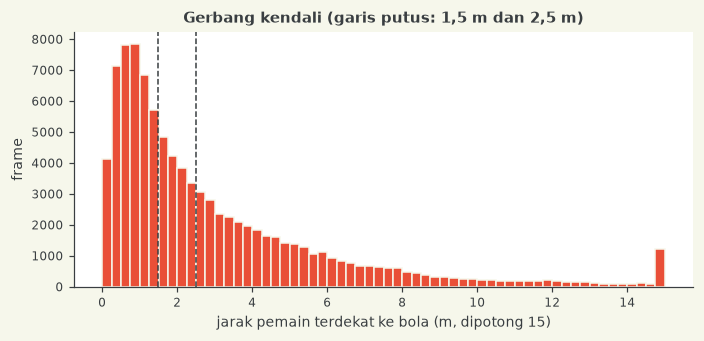

In [2]:
dist = common.team_distances(); dH, dA = dist[:, 0], dist[:, 1]
OBS = np.isfinite(dH) & np.isfinite(dA)
NEAR = np.where(OBS, np.minimum(dH, dA), np.inf)
E = np.zeros(N); E[OBS] = np.clip((dA[OBS] - dH[OBS]) / 3.0, -10, 10)
LPB_H, LPB_A = -np.logaddexp(0, -E), -np.logaddexp(0, E); LPB_H[~OBS] = 0; LPB_A[~OBS] = 0

rows = []
for r in (1.0, 1.5, 2.5, 5.0, np.inf):
    g = GRADED & OBS & (NEAR <= r)
    rows.append({"r (m)": r, "frame dinilai dengan bukti": f"{g.sum() / GRADED.sum():.1%}", "dari frame ber-bola": f"{g.sum() / (GRADED & OBS).sum():.1%}"})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(np.clip(NEAR[GRADED & OBS], 0, 15), bins=60, color=C1, edgecolor=C3)
for r in (1.5, 2.5): ax.axvline(r, color=INK, ls="--", lw=1)
ax.set(xlabel="jarak pemain terdekat ke bola (m, dipotong 15)", ylabel="frame", title="Gerbang kendali (garis putus: 1,5 m dan 2,5 m)")
fig.tight_layout(); plt.show()

Sebagian besar frame ber-bola punya pemain dalam jangkauan, tetapi ada porsi yang jelas di luar radius kendali: di frame itulah bukti lama memaksa keputusan padahal tidak ada yang menguasai bola.

## [2] Decoder dengan gerbang

Bukti bola pada frame di luar radius diganti nol. Bukti bentuk tim 008 tetap berlaku di semua frame. λ dikalibrasi per varian ke target eksternal.

In [3]:
G = common.gap_dead_ball(); DEAD = G[G.p_dead >= 0.5]
P_TCN = np.load(Path(common.CACHE) / "p_tcn.npy")
pc = np.clip(P_TCN, 1e-3, 1 - 1e-3); LS_H, LS_A = np.log(pc), np.log(1 - pc)

def finish(paths):
    lab = np.full(N, "X", dtype="<U1")
    for (half, a, b), p in zip(BLOCKS3, paths):
        lab[a:b + 1] = np.where(p == 0, "H", "A")
        if half == 2: lab[a:KICKOFF2] = "D"
    for _, r in DEAD.iterrows(): lab[int(r.f0):int(r.f1)] = "D"
    return lab

def decode(r, ks, lam):
    gate = NEAR <= r
    h = np.where(gate, LPB_H, 0.0) + ks * LS_H; a = np.where(gate, LPB_A, 0.0) + ks * LS_A
    return finish([common.viterbi_2state(h[x:y + 1], a[x:y + 1], lam) for x, y in BL])

def count(lab):
    n, gaps = 0, []
    for _, a, b in BLOCKS3:
        seg = lab[a:b + 1]; st = []
        for t in ("H", "A"):
            s_, e_ = common.runs(seg == t); st += list(s_)
        st = np.sort(st); n += len(st)
        if len(st) > 1: gaps += list(np.diff(st) / FPS)
    return n, np.array(gaps)

RATE, RATE_SD, _ = common.external_possession_rate()
TARGET, TARGET_SD = RATE * GRADED_MIN, RATE_SD * GRADED_MIN
SPEC = {"ref_ungated": (np.inf, 0.02), "gate25": (2.5, 0.02), "gate15": (1.5, 0.02), "gate15_noshape": (1.5, 0.0)}
LAMS = [3, 5, 10, 20, 30, 50, 80, 120, 200, 400]
SWEEP = {k: [(l, count(decode(r, ks, l))[0]) for l in LAMS] for k, (r, ks) in SPEC.items()}
def solve(sw, target):
    x = np.log([l for l, _ in sw]); y = np.array([n for _, n in sw], float)
    if target >= y[0]: return float(np.exp(x[0]))
    if target <= y[-1]: return float(np.exp(x[-1]))
    return float(np.exp(np.interp(-target, -y, x)))
CAL = {k: solve(v, TARGET) for k, v in SWEEP.items()}
print(f"target: {TARGET:.0f} +/- {TARGET_SD:.0f} possession")
display(pd.DataFrame({k: [n for _, n in v] for k, v in SWEEP.items()}, index=[f"λ={l}" for l in LAMS]).T)
display(pd.DataFrame({"λ*": CAL}).round(1))

target: 208 +/- 21 possession


,λ=3,λ=5,λ=10,λ=20,λ=30,λ=50,λ=80,λ=120,λ=200,λ=400
ref_ungated,845,668,477,306,246,194,147,131,116,78
gate25,539,453,333,236,195,150,127,112,90,64
gate15,428,361,271,202,172,131,117,98,84,58
gate15_noshape,366,296,229,189,161,124,106,91,80,59


,λ*
ref_ungated,43.6
gate25,26.4
gate15,18.8
gate15_noshape,14.4


Gerbang mengurangi jumlah frame yang memberi bukti, sehingga λ* bergeser. Perbandingan antar varian hanya adil pada λ yang sudah dikalibrasi ke target yang sama.

## [3] Varian yang dibangun dan pergeseran waktu pergantian (internal)

Selain jumlah dan durasi possession, dihitung **pergeseran waktu pergantian H↔A relatif terhadap varian tanpa gerbang**: untuk tiap pergantian di varian tanpa gerbang, selisih ke pergantian terdekat dengan tujuan sama di varian bergerbang. Ini murni internal (tanpa ground truth) dan hanya menunjukkan ke arah mana gerbang menggeser waktu.

In [4]:
VARS = {"v1_ref_ungated": "ref_ungated", "v2_gate25": "gate25", "v3_gate15": "gate15", "v4_gate15_noshape": "gate15_noshape"}
for old in OUT.glob("*.csv"): old.unlink()
LAB, rows = {}, []
for name, key in VARS.items():
    r_, ks_ = SPEC[key]; lab = decode(r_, ks_, CAL[key]); LAB[name] = lab; write_submission(str(OUT / f"{name}.csv"), lab)

def changes(lab):
    out = []
    for _, a, b in BLOCKS3:
        for i in range(a + 1, b + 1):
            if lab[i] != lab[i - 1] and lab[i] in ("H", "A") and lab[i - 1] in ("H", "A"): out.append((i, lab[i]))
    return out
REF = changes(LAB["v1_ref_ungated"])
for name, lab in LAB.items():
    n, g = count(lab)
    ch = changes(lab); sh = []
    for f, t in REF:
        c = [(h - f) for h, u in ch if u == t and abs(h - f) <= 10 * FPS]
        if c: sh.append(min(c, key=abs) / FPS)
    sh = np.array(sh)
    rows.append({"varian": name, "λ*": round(CAL[VARS[name]], 1), "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
                 "% D": round(100 * np.mean(lab[GRADED] == "D"), 1), "n H↔A": len(ch),
                 "geser median vs tanpa gerbang (dtk)": round(float(np.median(sh)), 2) if len(sh) else None, "ditemukan": len(sh)})
codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1"); sm = smooth(codes, 50)
for _, a, b in BLOCKS3: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, g = count(base)
rows.append({"varian": "baseline_smooth50", "λ*": None, "possession": n, "median awal-ke-awal (dtk)": round(float(np.median(g)), 1),
             "% D": round(100 * np.mean(base[GRADED] == "D"), 1), "n H↔A": None, "geser median vs tanpa gerbang (dtk)": None, "ditemukan": None})
display(pd.DataFrame(rows))

,varian,λ*,possession,median awal-ke-awal (dtk),% D,n H↔A,geser median vs tanpa gerbang (dtk),ditemukan
0,v1_ref_ungated,43.6,219,19.7,22.7,180.0,0.00,180.0
1,v2_gate25,26.4,206,23.7,22.7,167.0,0.00,151.0
2,v3_gate15,18.8,211,22.2,22.7,172.0,0.00,145.0
3,v4_gate15_noshape,14.4,209,20.4,22.7,170.0,-0.24,140.0
4,baseline_smooth50,NaN,594,5.7,32.3,NaN,NaN,NaN


Pergeseran median positif berarti pergantian bergerbang terjadi **lebih lambat** daripada tanpa gerbang, yang searah dengan definisi "kendali". Ukuran pergeseran bergantung pada radius, dan tidak ada target "benar" yang bisa diambil dari data ini tanpa ground truth.

## [4] Validasi, skor, dan diagnostik keterlambatan (pemeriksaan pipeline)

Skor GT publik hanya memeriksa pipeline; dengan 17 possession selisih kecil adalah noise. Diagnostik keterlambatan (selisih bertanda antara pergantian prediksi dan GT) hanya menjelaskan perilaku dan **tidak dipakai untuk memilih radius**; radius sudah ditetapkan di atas dari prior fisik.

In [5]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])
subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT), "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

gt = pm.read_label_csv(ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv")["label"].astype(str).values
a0, b0 = 11185, 18684
GT_CH = [(i, gt[i]) for i in range(a0 + 1, b0 + 1) if gt[i] != gt[i - 1] and gt[i] in ("H", "A") and gt[i - 1] in ("H", "A")]
drows = []
for name, lab in LAB.items():
    ch = [(i, lab[i]) for i in range(a0 + 1, b0 + 1) if lab[i] != lab[i - 1] and lab[i] in ("H", "A") and lab[i - 1] in ("H", "A")]
    d = []
    for f, t in GT_CH:
        c = [(h - f) for h, u in ch if u == t and abs(h - f) <= 10 * FPS]
        if c: d.append(min(c, key=abs) / FPS)
    d = np.array(d)
    drows.append({"varian": name, "H↔A GT": len(GT_CH), "ditemukan (≤10 dtk)": len(d), "median keterlambatan (dtk)": round(float(np.median(d)), 2) if len(d) else None,
                  "|dt| ≤ 2 dtk": f"{np.mean(np.abs(d) <= 2):.0%}" if len(d) else None})
display(pd.DataFrame(drows))

baseline_smooth50.csv -> VALID


v1_ref_ungated.csv -> VALID


v2_gate25.csv -> VALID


v3_gate15.csv -> VALID


v4_gate15_noshape.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v2_gate25,0.6730,0.5286,11,25.9418
1,2,v3_gate15,0.6685,0.5286,11,25.9418
2,3,v1_ref_ungated,0.6651,0.5000,11,25.9418
3,4,v4_gate15_noshape,0.6557,0.3846,9,31.7067
4,5,baseline_smooth50,0.6207,0.3256,26,10.8031


,varian,H↔A GT,ditemukan (≤10 dtk),median keterlambatan (dtk),|dt| ≤ 2 dtk
0,v1_ref_ungated,12,7,-2.20,29%
1,v2_gate25,12,7,-1.36,57%
2,v3_gate15,12,7,-1.60,57%
3,v4_gate15_noshape,12,6,-1.94,33%


# Ringkasan 011

**Yang dikerjakan.** Bukti bola (pemain terdekat) sekarang hanya dihitung bila pemain terdekat berada dalam radius kendali *r* dari bola; di luar radius tidak ada bukti dan keadaan bertahan. Radius ditetapkan dari prior fisik sebelum melihat hasil: 1,5 m (utama) dan 2,5 m (alternatif longgar). Bukti bentuk tim TCN dari 008 (κ = 0,02) tetap dipakai, gap bola mati dari 004 tetap, dan λ dikalibrasi ulang ke target eksternal 006 untuk tiap varian. Semua lima berkas lolos `validate_submission.py`. Tidak ada label tangan, tidak ada GT yang dipakai untuk memilih radius, tidak ada data keluar dari mesin.

**Hasil internal.**
1. **Gerbang menyaring bukti secara substansial.** Hanya 24,8% frame dinilai (41,9% frame ber-bola) lolos pada r = 1,5 m, dan 35,1% (59,2%) pada r = 2,5 m, dibanding 59,2% tanpa gerbang. Sisanya adalah frame ketika bola melayang atau diperebutkan jauh dari semua pemain.
2. **λ* turun** (43,6 tanpa gerbang, 26,4 pada 2,5 m, 18,8 pada 1,5 m) karena bukti per frame lebih sedikit dan lebih bersih; jumlah possession tetap sesuai target (206 sampai 211, median awal-ke-awal 22 sampai 24 detik, acuan 22,3 detik).
3. **Waktu pergantian H↔A hampir tidak bergeser** relatif terhadap varian tanpa gerbang (median pergeseran 0,00 dtk pada 145 sampai 151 dari 180 pergantian yang cocok dalam 10 detik). Artinya gerbang mengubah *beberapa* pergantian, bukan menggeser semuanya secara seragam.

**Diagnostik keterlambatan pada GT publik (bukan dasar pemilihan; 7 dari 12 pergantian H↔A ditemukan).**

| varian | median keterlambatan | \|dt\| ≤ 2 dtk |
|---|---|---|
| tanpa gerbang (`v1`) | −2,20 dtk | 29% |
| gerbang 2,5 m (`v2`) | −1,36 dtk | 57% |
| gerbang 1,5 m (`v3`) | −1,60 dtk | 57% |
| gerbang 1,5 m tanpa bentuk tim (`v4`) | −1,94 dtk | 33% |

Arahnya sesuai dugaan (pergantian kurang terlalu awal) pada kedua radius, tetapi dasarnya hanya tujuh pergantian, jadi ini petunjuk, bukan bukti.

**Pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v2_gate25` 0,673 macroF1 dan 0,529 spellF1; `v3_gate15` 0,669 dan 0,529; `v1_ref_ungated` 0,665 dan 0,500; `v4_gate15_noshape` 0,656 dan 0,385; `baseline_smooth50` 0,621 dan 0,326. Kenaikan 0,03 pada spellF1 adalah beda satu possession dan berada di dalam noise (satu possession menggeser skor sekitar enam poin), jadi **tidak ada klaim perbaikan yang terbukti**.

**Catatan.** Dua radius memberi hasil serupa, dan saya tidak memilih berdasarkan GT publik: radius utama tetap 1,5 m sebagaimana ditetapkan di awal. Bukti bentuk tim memang membantu pada varian bergerbang (v4 tanpa bentuk tim lebih buruk), konsisten dengan 008.

**Langkah berikutnya.** (a) Satu skrip yang membangun berkas akhir dari data (syarat reproduksibilitas); (b) uji kestabilan ke radius lain dan ke acuan eksternal lain; (c) dokumen teknis.